In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Path to your processed player-season dataset
PATH = "../../statsbomb_pipeline/data/processed/player_season_model_dataset.csv"

df = pd.read_csv(PATH)

# Filter to players with enough minutes (same rule as PCA)
MIN_MINUTES = 900
model_df = df[df["minutes_played_total"] >= MIN_MINUTES].copy()

# Target variable: total expected goals
target_col = "xg_total"

# Candidate single predictors to explore
candidate_predictors = [
    "xThreat_total",
    "xThreat_pass_total",
    "xThreat_carry_total",
]

# Drop rows with missing data in target or any candidate predictor
model_df = model_df.dropna(subset=[target_col] + candidate_predictors).copy()

print("Sample size after filtering:", model_df.shape[0])


Sample size after filtering: 324


In [8]:
def fit_simple_lr(df, predictor, target, test_size=0.2, random_state=42, verbose=True):
    X = df[[predictor]].values  # single predictor as 2D array
    y = df[target].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    r2_train = r2_score(y_train, y_pred_train)
    r2_test = r2_score(y_test, y_pred_test)
    rmse_train = mean_squared_error(y_train, y_pred_train) ** 0.5
    rmse_test = mean_squared_error(y_test, y_pred_test) ** 0.5


    if verbose:
        print(f"=== Simple Linear Regression: {target} ~ {predictor} ===")
        print(f"Coefficient (slope): {model.coef_[0]:.4f}")
        print(f"Intercept:          {model.intercept_:.4f}")
        print(f"R^2 (train):        {r2_train:.4f}")
        print(f"R^2 (test):         {r2_test:.4f}")
        print(f"RMSE (train):       {rmse_train:.4f}")
        print(f"RMSE (test):        {rmse_test:.4f}")
        print()

    return {
        "predictor": predictor,
        "coef": model.coef_[0],
        "intercept": model.intercept_,
        "r2_train": r2_train,
        "r2_test": r2_test,
        "rmse_train": rmse_train,
        "rmse_test": rmse_test,
        "model": model,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "y_pred_test": y_pred_test,
    }


In [10]:
results = []

for pred in candidate_predictors:
    res = fit_simple_lr(model_df, pred, target_col)
    results.append(res)

# Summary table
summary = pd.DataFrame([{
    "predictor": r["predictor"],
    "coef": r["coef"],
    "R2_train": r["r2_train"],
    "R2_test": r["r2_test"],
    "RMSE_train": r["rmse_train"],
    "RMSE_test": r["rmse_test"],
} for r in results])

summary


=== Simple Linear Regression: xg_total ~ xThreat_total ===
Coefficient (slope): 0.2161
Intercept:          2.1699
R^2 (train):        0.0126
R^2 (test):         0.0308
RMSE (train):       3.4368
RMSE (test):        3.1002

=== Simple Linear Regression: xg_total ~ xThreat_per90 ===
Coefficient (slope): 1.1858
Intercept:          2.5799
R^2 (train):        0.0005
R^2 (test):         0.0037
RMSE (train):       3.4578
RMSE (test):        3.1432

=== Simple Linear Regression: xg_total ~ xThreat_carry_total ===
Coefficient (slope): 1.5296
Intercept:          2.1186
R^2 (train):        0.0589
R^2 (test):         0.0159
RMSE (train):       3.3552
RMSE (test):        3.1238



,predictor,coef,R2_train,R2_test,RMSE_train,RMSE_test
0,xThreat_total,0.216114,0.012570,0.030762,3.436839,3.100169
1,xThreat_per90,1.185823,0.000490,0.003657,3.457799,3.143220
2,xThreat_carry_total,1.529632,0.058945,0.015949,3.355163,3.123771


Best single predictor based on test R^2: xThreat_total


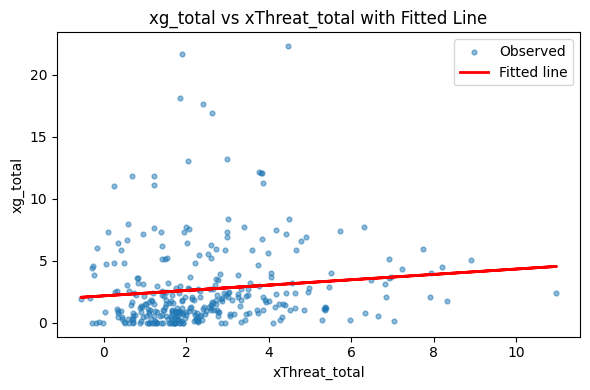

In [11]:
best_pred = summary.sort_values("R2_test", ascending=False).iloc[0]["predictor"]
print("Best single predictor based on test R^2:", best_pred)

# Grab that result dict
best_result = next(r for r in results if r["predictor"] == best_pred)
model = best_result["model"]

# Use full data for a clean line
X_full = model_df[[best_pred]].values
y_full = model_df[target_col].values
y_full_pred = model.predict(X_full)

plt.figure(figsize=(6, 4))
plt.scatter(X_full, y_full, alpha=0.5, s=12, label="Observed")
plt.plot(X_full, y_full_pred, color="red", linewidth=2, label="Fitted line")
plt.xlabel(best_pred)
plt.ylabel(target_col)
plt.title(f"{target_col} vs {best_pred} with Fitted Line")
plt.legend()
plt.tight_layout()
plt.show()
